<a href="https://colab.research.google.com/github/caymanq/iqc-competition/blob/main/ClassicalModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import networkx as nx

economy = nx.Graph()

economy.add_node("Healthcare—Texas", resistance=0.75)
economy.add_node("Insurance—Texas", resistance=0.55)
economy.add_node("Banking—Texas", resistance=0.45)

economy.add_edge(
    "Healthcare—Texas", "Insurance—Texas", strength=0.15 * 1.0
)
economy.add_edge(
    "Insurance—Texas", "Banking—Texas", strength=0.15 * 0.5
)


100 nodes

In [4]:
def solve_year(economy, year):
    pressure = 0.07 * (year - 2026)

    graph = nx.DiGraph()
    source, sink = object(), object()
    graph.add_nodes_from([source, sink])

    for node, data in economy.nodes(data=True):
        field = pressure - data["resistance"]

        graph.add_edge(source, node, capacity=2 * max(field, 0))
        graph.add_edge(node, sink, capacity=2 * max(-field, 0))

    for u, v, data in economy.edges(data=True):
        strength = data["strength"]
        if strength < 0:
            raise ValueError("This method requires nonnegative ties.")

        # Only one direction crosses from source-side to sink-side.
        graph.add_edge(u, v, capacity=2 * strength)
        graph.add_edge(v, u, capacity=2 * strength)

    _, (digital_side, paper_side) = nx.minimum_cut(
        graph, source, sink
    )

    return {
        node: 1 if node in digital_side else -1
        for node in economy.nodes
    }

In [5]:
flip_years = {node: None for node in economy.nodes}

for year in range(2026, 2041):
    states = solve_year(economy, year)

    for node, state in states.items():
        if state == 1 and flip_years[node] is None:
            flip_years[node] = year

print(flip_years)

{'Healthcare—Texas': 2035, 'Insurance—Texas': 2035, 'Banking—Texas': 2034}


20 Nodes

In [6]:
import networkx as nx

resistances = {
    "Technology": 0.10,
    "Media": 0.20,
    "Telecom": 0.25,
    "Retail": 0.30,
    "Hospitality": 0.35,
    "Logistics": 0.40,
    "Banking": 0.45,
    "Accounting": 0.50,
    "Manufacturing": 0.50,
    "Insurance": 0.55,
    "Energy": 0.55,
    "Pharma": 0.60,
    "Education": 0.60,
    "Nonprofit": 0.65,
    "Real Estate": 0.65,
    "Construction": 0.70,
    "Agriculture": 0.70,
    "Healthcare": 0.75,
    "Government": 0.85,
    "Legal": 0.90,
}

# Relative relationship strengths supplied by the challenge.
partner_ties = [
    ("Healthcare", "Insurance", 1.0),
    ("Manufacturing", "Logistics", 0.9),
    ("Banking", "Real Estate", 0.8),
    ("Retail", "Logistics", 0.8),
    ("Construction", "Real Estate", 0.8),
    ("Healthcare", "Pharma", 0.7),
    ("Legal", "Real Estate", 0.7),
    ("Healthcare", "Government", 0.6),
    ("Legal", "Government", 0.6),
    ("Accounting", "Banking", 0.6),
    ("Government", "Education", 0.6),
    ("Agriculture", "Logistics", 0.6),
    ("Telecom", "Technology", 0.6),
    ("Insurance", "Banking", 0.5),
    ("Legal", "Banking", 0.5),
    ("Energy", "Manufacturing", 0.5),
    ("Technology", "Media", 0.5),
    ("Insurance", "Legal", 0.4),
    ("Accounting", "Nonprofit", 0.4),
    ("Construction", "Government", 0.4),
    ("Hospitality", "Retail", 0.4),
    ("Pharma", "Logistics", 0.4),
    ("Nonprofit", "Education", 0.4),
    ("Media", "Retail", 0.3),
]

economy = nx.Graph()
region = "Texas"

for industry, resistance in resistances.items():
    economy.add_node(
        industry,
        industry=industry,
        region=region,
        resistance=resistance,
    )

for industry_a, industry_b, relative_strength in partner_ties:
    economy.add_edge(
        industry_a,
        industry_b,
        strength=0.15 * relative_strength,
    )

print(
    f"{economy.number_of_nodes()} industries, "
    f"{economy.number_of_edges()} partner ties"
)

20 industries, 24 partner ties


In [7]:
flip_years = {industry: None for industry in economy.nodes}

for year in range(2026, 2041):
    states = solve_year(economy, year)

    for industry, state in states.items():
        if state == 1 and flip_years[industry] is None:
            flip_years[industry] = year

# Display industries in order of adoption.
for industry, year in sorted(
    flip_years.items(),
    key=lambda item: (
        item[1] if item[1] is not None else float("inf"),
        item[0],
    ),
):
    print(f"{industry:15} {year if year is not None else 'After 2040'}")

Media           2029
Technology      2029
Telecom         2029
Hospitality     2032
Retail          2032
Energy          2034
Logistics       2034
Manufacturing   2034
Agriculture     2035
Accounting      2036
Banking         2036
Construction    2036
Education       2036
Government      2036
Healthcare      2036
Insurance       2036
Legal           2036
Nonprofit       2036
Pharma          2036
Real Estate     2036


100 Nodes (Test)

In [8]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# Define the regions and their adjacencies (to add cross-region ties)
regions = ["Texas", "California", "Southwest", "Mountain West", "Pacific NW"]

# We will connect neighboring regions with weak ties for the same industries.
# Let's define a simple adjacency graph for regions
region_adj = [
    ("Texas", "Southwest"),
    ("Southwest", "California"),
    ("Southwest", "Mountain West"),
    ("Mountain West", "Pacific NW"),
    ("California", "Pacific NW"),
]

# Base resistances
base_resistances = {
    "Technology": 0.10,
    "Media": 0.20,
    "Telecom": 0.25,
    "Retail": 0.30,
    "Hospitality": 0.35,
    "Logistics": 0.40,
    "Banking": 0.45,
    "Accounting": 0.50,
    "Manufacturing": 0.50,
    "Insurance": 0.55,
    "Energy": 0.55,
    "Pharma": 0.60,
    "Education": 0.60,
    "Nonprofit": 0.65,
    "Real Estate": 0.65,
    "Construction": 0.70,
    "Agriculture": 0.70,
    "Healthcare": 0.75,
    "Government": 0.85,
    "Legal": 0.90,
}

# Regional shifts (about ±0.15)
regional_shifts = {
    "Texas": -0.05,
    "California": -0.12,  # Tech-forward, lower overall resistance
    "Southwest": 0.05,
    "Mountain West": 0.02,
    "Pacific NW": -0.08,
}

# Partner ties (relative strengths)
partner_ties = [
    ("Healthcare", "Insurance", 1.0),
    ("Manufacturing", "Logistics", 0.9),
    ("Banking", "Real Estate", 0.8),
    ("Retail", "Logistics", 0.8),
    ("Construction", "Real Estate", 0.8),
    ("Healthcare", "Pharma", 0.7),
    ("Legal", "Real Estate", 0.7),
    ("Healthcare", "Government", 0.6),
    ("Legal", "Government", 0.6),
    ("Accounting", "Banking", 0.6),
    ("Government", "Education", 0.6),
    ("Agriculture", "Logistics", 0.6),
    ("Telecom", "Technology", 0.6),
    ("Insurance", "Banking", 0.5),
    ("Legal", "Banking", 0.5),
    ("Energy", "Manufacturing", 0.5),
    ("Technology", "Media", 0.5),
    ("Insurance", "Legal", 0.4),
    ("Accounting", "Nonprofit", 0.4),
    ("Construction", "Government", 0.4),
    ("Hospitality", "Retail", 0.4),
    ("Pharma", "Logistics", 0.4),
    ("Nonprofit", "Education", 0.4),
    ("Media", "Retail", 0.3),
]

multi_economy = nx.Graph()

# 1. Add all nodes across regions with shifts and noise
for r in regions:
    shift = regional_shifts[r]
    for ind, base_res in base_resistances.items():
        # base + regional shift + small random noise
        noise = np.random.uniform(-0.02, 0.02)
        final_res = clip_res = max(0.01, min(0.99, base_res + shift + noise))

        node_name = f"{ind}—{r}"
        multi_economy.add_node(
            node_name,
            industry=ind,
            region=r,
            resistance=final_res
        )

# 2. Add intra-region partner ties (strength = 0.15 * relative_strength)
for r in regions:
    for ind_a, ind_b, rel_strength in partner_ties:
        node_a = f"{ind_a}—{r}"
        node_b = f"{ind_b}—{r}"
        multi_economy.add_edge(
            node_a,
            node_b,
            strength=0.15 * rel_strength
        )

# 3. Add inter-region weak ties for same industry between neighboring regions
for reg_a, reg_b in region_adj:
    for ind in base_resistances.keys():
        node_a = f"{ind}—{reg_a}"
        node_b = f"{ind}—{reg_b}"
        multi_economy.add_edge(
            node_a,
            node_b,
            strength=0.05  # As suggested in spec
        )

print(f"Scaled Network: {multi_economy.number_of_nodes()} nodes, {multi_economy.number_of_edges()} edges.")

Scaled Network: 100 nodes, 220 edges.


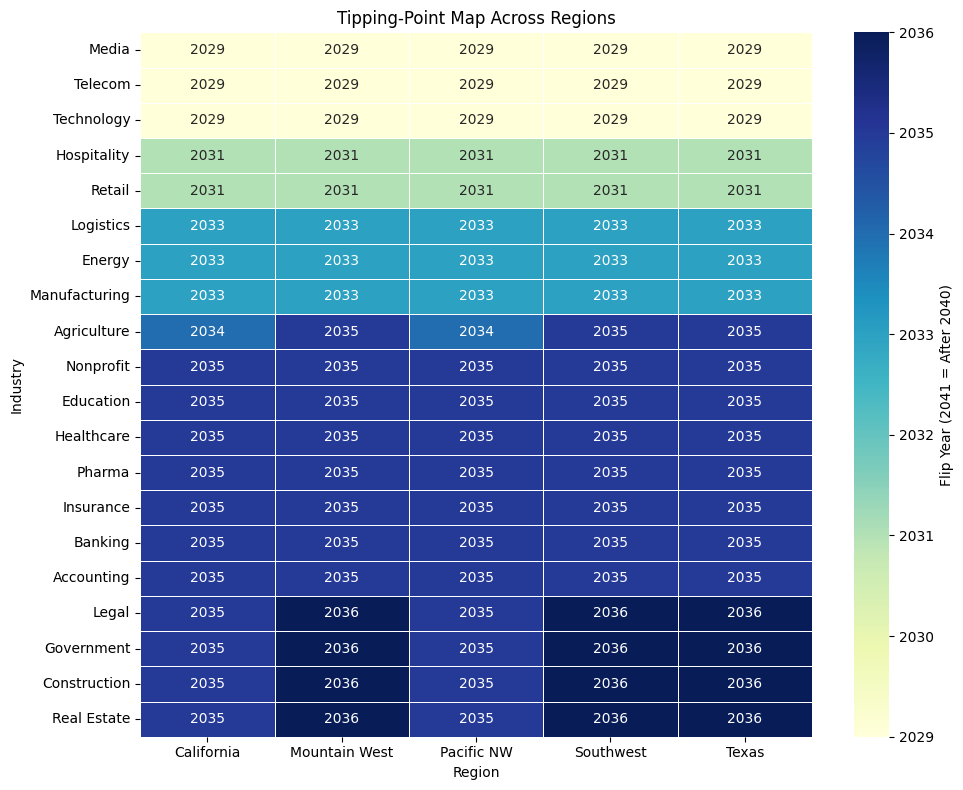

In [9]:
# Calculate the flip years for the scaled multi-region network
flip_years_multi = {node: None for node in multi_economy.nodes}

for year in range(2026, 2041):
    states = solve_year(multi_economy, year)
    for node, state in states.items():
        if state == 1 and flip_years_multi[node] is None:
            flip_years_multi[node] = year

# Reformat data into a DataFrame for visualization
data_records = []
for node, year in flip_years_multi.items():
    industry, region = node.split("—")
    data_records.append({
        "Industry": industry,
        "Region": region,
        "Flip Year": year if year is not None else 2041
    })

df_pivot = pd.DataFrame(data_records).pivot(index="Industry", columns="Region", values="Flip Year")

# Order industries by average flip year across all regions for a cleaner presentation
order = df_pivot.mean(axis=1).sort_values().index
df_pivot = df_pivot.loc[order]

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_pivot,
    annot=True,
    fmt="g",
    cmap="YlGnBu",
    cbar_kws={'label': 'Flip Year (2041 = After 2040)'},
    linewidths=.5
)
plt.title("Tipping-Point Map Across Regions")
plt.ylabel("Industry")
plt.xlabel("Region")
plt.tight_layout()
plt.show()